# 22 · Open image boundaries and valid support

Separate an observed zero from a missing pixel. Replace toroidal translations with finite overlap. Compare the pixel and Q fields using the same support rule and the same allowed search.

The periodic shift wraps an edge stroke. The finite shift removes it and marks incoming samples as unobserved. The finite lag-one moment is zero in the edge-pair control.

In [1]:
from pathlib import Path
import sys, json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.open_images import COMPONENTS,Observation,translate,describe,open_moment,similarity_profile
from observables.stage6 import CONDITIONS,SEED,load_data,galleries,view,run,paired_interval
OUT=ROOT/'results'/'stage6'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

Matplotlib is building the font cache; this may take a moment.


## Show what crosses an edge
The right-edge line exits the finite canvas under a three-pixel shift. The periodic comparison wraps it into the opposite edge. In the finite case the incoming strip is unobserved. It is displayed in blue and excluded from local derivatives and overlap comparisons.

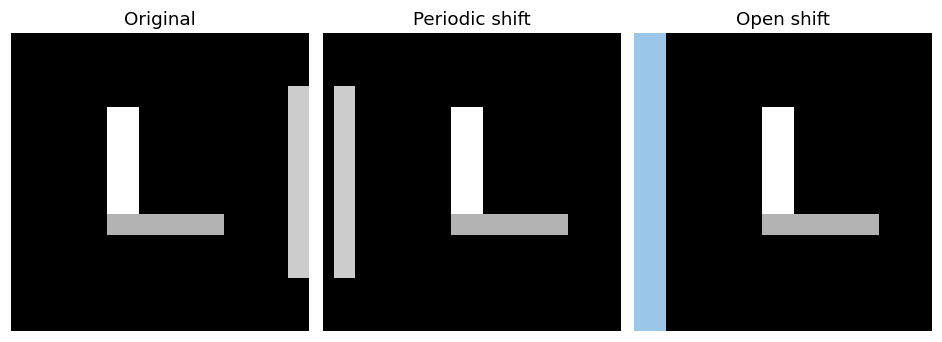

In [3]:
a=np.zeros((28,28))
a[7:19,9:12]=1
a[17:19,9:20]=.7
a[5:23,26:]=.8
ref=Observation.full(a)
open_shift=translate(ref,(0,3))
periodic=np.roll(a,3,axis=1)
fig,axes=plt.subplots(1,3,figsize=(8.5,3))
cmap=plt.get_cmap('gray').with_extremes(bad='#9ac7e7')
for ax,x,title in zip(axes,[a,periodic,np.where(open_shift.valid,open_shift.image,np.nan)],
                      ['Original','Periodic shift','Open shift']):
    ax.imshow(x,cmap=cmap,vmin=0,vmax=1);ax.set_title(title);ax.set_axis_off()
show('22_open_shift')
assert periodic[:,:3].sum()>0 and not open_shift.valid[:,:3].any()

## Derive two independent checks
A pair of marks on the left and right edges is adjacent at lag one only on the torus. A flat field with its left border cropped stays flat across the observed region. Its boundary has no derivative into missing pixels.

In [5]:
from observables.open_images import finite_gradient
edge=np.zeros((28,28));edge[12,[0,-1]]=1
mask=np.ones_like(edge,dtype=bool)
cyclic=np.mean(edge*np.roll(edge,1,axis=1))
open_value=open_moment(edge,mask,[(0,0),(0,1)])
print('Lag-one product average · cyclic:',cyclic,'· finite:',open_value)
assert open_value==0 and cyclic>0
mask[:,:6]=False
flat=np.where(mask,1.,0.)
assert np.max(abs(finite_gradient(flat,mask)))==0
print('Largest gradient on the cropped flat field:',np.max(abs(finite_gradient(flat,mask))))

Lag-one product average · cyclic: 0.0012755102040816326 · finite: 0.0
Largest gradient on the cropped flat field: 0.0


## Alignment compares only jointly observed pixels
Search integer offsets within ±3 in both axes and require at least 65% of the full canvas to be jointly observed. For a field f, the relative distance is the norm of the difference divided by the sum of the two norms, all evaluated on that shared support. Pixels and the local nematic field each choose their best eligible offset. Both return the offset and fraction of the full canvas used. They can choose different alignments.

In [7]:
scores,offsets,coverage=similarity_profile(open_shift,ref)
display(pd.Series(scores,name='agreement').round(6))
display(pd.DataFrame({'offset_y':offsets[:,0],'offset_x':offsets[:,1],'coverage':coverage},
                     index=['pixels','local Q']))
assert np.isclose(scores['aligned pixels'],1)
assert coverage[0]<1

pixels             0.344003
polar m1           0.000000
global Q           0.668860
angular m4         0.985048
HOG                0.536064
local Q            0.477537
open Q pairs       0.810215
open Q triplets    0.528635
DCT power          0.439663
aligned pixels     1.000000
aligned local Q    0.773472
Name: agreement, dtype: float64

,offset_y,offset_x,coverage
pixels,0,-3,0.892857
local Q,0,-3,0.892857


Perfect pixel agreement here means agreement on the overlap. It cannot recover the line that left the canvas. The Q field uses local gradient neighborhoods and can disagree near a changed observation boundary. Each local Q measurement is damped in weak-gradient regions. Full-field descriptors and registered overlap descriptors answer different questions.